In [43]:
import json
import os
import random
import re
import unicodedata
from collections import Counter, defaultdict
from urllib.parse import urlparse
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import pandas as pd
import seaborn as sns

from query_executor import run_query
from query_generator import ALCOHOL_WORDS, build_required

In [3]:
RAW_FILE = "data/brands_raw.csv"
CLEANED_FILE = "data/brands_cleaned.csv"
REVIEW_FILE = "data/review_urls.csv"
NOT_FOUND_FILE = "data/urls_not_found.csv"
FINAL_FILE = "data/kleniec.json"
NO_DICTIONARY_FILE = "data/no_dictionary_results.csv"

SOURCE_NAMES = ["source1", "source2", "source3", "source4", "source5"]

raw_df = pd.read_csv(RAW_FILE)
cleaned_df = pd.read_csv(CLEANED_FILE)
review_df = pd.read_csv(REVIEW_FILE, encoding="utf-8-sig")
not_found_df = pd.read_csv(NOT_FOUND_FILE)

with open(FINAL_FILE, encoding="utf-8") as file:
    final_queries = json.load(file)["results"]

review_df["urls"] = review_df["urls"].apply(json.loads)

### Number of Brands at Each Stage

In [4]:
brands_count = pd.DataFrame([{
    "raw_brands": len(raw_df),
    "cleaned_brands": len(cleaned_df),
    "with_urls": len(review_df),
    "approved": len(final_queries),
}])
brands_count

,raw_brands,cleaned_brands,with_urls,approved
0,1071,1069,127,126


### Total number of urls returned by estimator per source and number of different brands detected per source

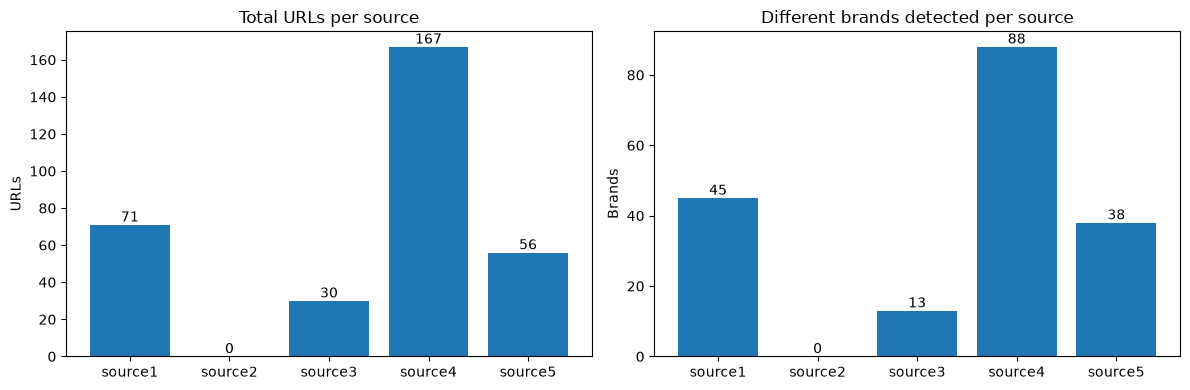

In [5]:
total_links = review_df[SOURCE_NAMES].sum()
brands_per_source = (review_df[SOURCE_NAMES] > 0).sum()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(SOURCE_NAMES, total_links)
axes[0].set_title("Total URLs per source")
axes[0].set_ylabel("URLs")

axes[1].bar(SOURCE_NAMES, brands_per_source)
axes[1].set_title("Different brands detected per source")
axes[1].set_ylabel("Brands")

for axis, values in zip(axes, [total_links, brands_per_source]):
    for position, value in enumerate(values):
        axis.text(position, value, str(value), ha="center", va="bottom")

plt.tight_layout()
plt.show()

### Share of brands that got at least one URL, by number of words in name

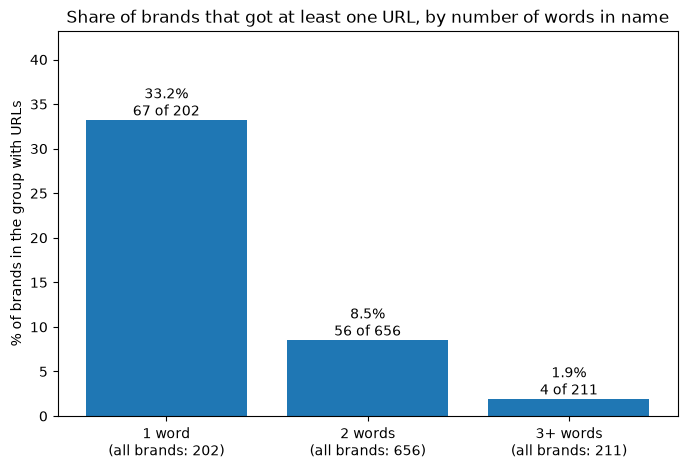

,found,total,percent_found
words,,,
1,67,202,33.2
2,56,656,8.5
3,4,211,1.9


In [7]:
all_brands = pd.concat([
    review_df[["brand"]].assign(found=True),
    not_found_df[["brand"]].assign(found=False),
])
all_brands["words"] = all_brands["brand"].str.split().str.len().clip(upper=3)

word_stats = all_brands.groupby("words")["found"].agg(["sum", "count"])
word_stats = word_stats.rename(columns={"sum": "found", "count": "total"})
word_stats["percent_found"] = (word_stats["found"] / word_stats["total"] * 100).round(1)

group_names = ["1 word", "2 words", "3+ words"]
labels = [f"{name}\n(all brands: {total})" for name, total in zip(group_names, word_stats["total"])]

plt.figure(figsize=(8, 5))
plt.bar(labels, word_stats["percent_found"])
for position, row in enumerate(word_stats.itertuples()):
    plt.text(position, row.percent_found, f"{row.percent_found}%\n{row.found} of {row.total}", ha="center", va="bottom")
plt.title("Share of brands that got at least one URL, by number of words in name")
plt.ylabel("% of brands in the group with URLs")
plt.ylim(0, word_stats["percent_found"].max() + 10)
plt.show()

word_stats

### Top 5 from alcohol-related words dictionary that appeared in found URLs

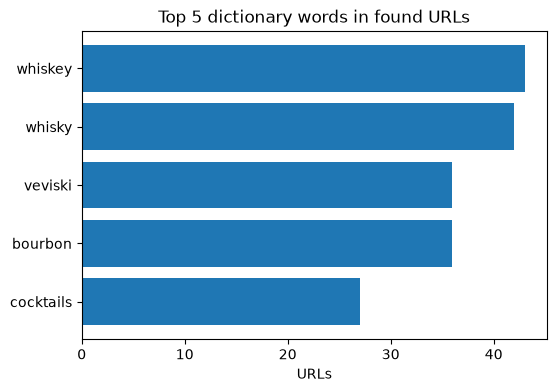

In [9]:
def find_dictionary_words(url):
    url = url.lower()
    found_words = []
    for word in ALCOHOL_WORDS:
        pattern = r"(?<![a-z])" + re.escape(word) + r"(?![a-z])"
        if re.search(pattern, url):
            found_words.append(word)
    return found_words


word_counter = Counter()

for urls in review_df["urls"]:
    for url in urls:
        word_counter.update(find_dictionary_words(url))

top_words = word_counter.most_common(5)

plt.figure(figsize=(6, 4))
plt.barh([word for word, count in top_words][::-1], [count for word, count in top_words][::-1])
plt.title("Top 5 dictionary words in found URLs")
plt.xlabel("URLs")
plt.show()

### Top 10 brands by number of URLs found

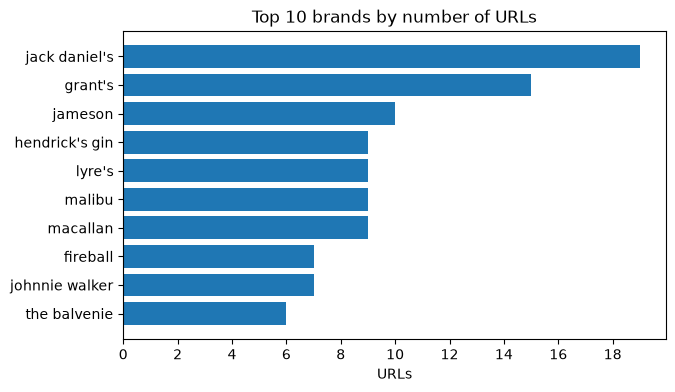

In [15]:
top_brands = review_df.sort_values("count", ascending=False).head(10)[["brand", "count"]]

plt.figure(figsize=(7, 4))
plt.barh(top_brands["brand"][::-1], top_brands["count"][::-1])
plt.title("Top 10 brands by number of URLs")
plt.xlabel("URLs")
plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))
plt.show()


### Top 5 domains in found URLs

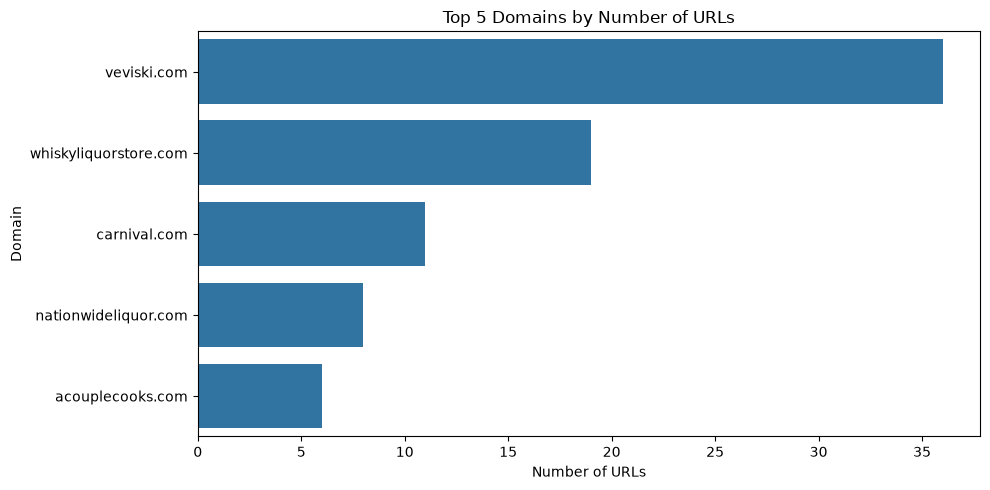

In [44]:
domain_counter = Counter()
for urls in review_df["urls"]:
    for url in urls:
        domain_counter[get_domain(url)] += 1

top_domains = pd.DataFrame(
    domain_counter.most_common(5),
    columns=["domain", "urls"]
)

plt.figure(figsize=(10, 5))
sns.barplot(data=top_domains, x="urls", y="domain")
plt.xlabel("Number of URLs")
plt.ylabel("Domain")
plt.title("Top 5 Domains by Number of URLs")
plt.tight_layout()
plt.show()

### Queries without the dictionary for 50 random brands that were not found

The query contains only `required`, without `optional`.
For each brand the first 30 URLs are printed, so we can check by hand whether removing the dictionary gives relevant results.

In [30]:
def build_query_without_dictionary(brand):
    return {"id": brand, "required": build_required(brand)}


random.seed(666)
sample_brands = random.sample(list(not_found_df["brand"]), 50)
brands_with_urls = 0

for brand in sample_brands:
    query = build_query_without_dictionary(brand)
    try:
        urls, source_counts = run_query(query)
    except Exception as error:
        print(f"{brand}: ERROR {error}")
        continue
    print(f"{brand}: {len(urls)} urls")
    for url in urls[:30]:
        print("   ", url)
    if urls:
        brands_with_urls += 1

print(f"Brands with at least one URL: {brands_with_urls} of {len(sample_brands)}")

pink whitney: 0 urls
ypioca cachaca: 0 urls
nantou omar: 0 urls
papi wines: 0 urls
king car: 0 urls
rabbit hole: 78 urls
    https://gtaforums.com/topic/986762-gta-6-speculation-discussion-part-8-the-rabbit-hole/page/779/
    https://www.countryliving.com/life/entertainment/a43428011/rabbit-hole-episode-guide/#
    https://www.stuff.co.nz/entertainment/stuff-to-watch/300884631/the-great-comedy-debate-tries-to-take-down-the-internet-but-dai-henwood-takes-them-down-a-foreskin-rabbit-hole
    https://readysteadycut.com/2023/05/15/rabbit-hole-season-2/
    https://www.comingsoon.it/serietv/rabbit-hole/3483/scheda
    https://www.telegraph.co.uk/radio/podcasts/charles-spencer-rabbit-hole-detectives-podcast
    https://www.theguardian.com/tv-and-radio/2023/mar/27/tv-review-rabbit-hole
    https://www.wattpad.com/1094884382-down-the-rabbit-hole-chapter-one-down-we-go/page/2
    http://places.singleplatform.com/the-rabbit-hole-3/menu
    https://123moviesfree.press/tvshows/rabbit-hole/
    htt

### All brands queried without the dictionary

The estimator is called for every cleaned brand with only `required` in the query (no `optional`). At the end we compare the total number of URLs with and without the dictionary.

In [27]:
if os.path.exists(NO_DICTIONARY_FILE):
    no_dictionary_df = pd.read_csv(NO_DICTIONARY_FILE, encoding="utf-8-sig")
else:
    rows = []
    brands = list(cleaned_df["brand"])
    for number, brand in enumerate(brands, start=1):
        query = build_query_without_dictionary(brand)
        if not query["required"]:
            continue
        try:
            urls, source_counts = run_query(query)
        except Exception as error:
            print(f"[{number}/{len(brands)}] {brand}: ERROR {error}")
            continue
        rows.append({"brand": brand, "count": len(urls), "urls": json.dumps(urls)})
        print(f"[{number}/{len(brands)}] {brand}: {len(urls)} urls")
    no_dictionary_df = pd.DataFrame(rows)
    no_dictionary_df.to_csv(NO_DICTIONARY_FILE, index=False, encoding="utf-8-sig")

no_dictionary_df["urls"] = no_dictionary_df["urls"].apply(json.loads)

total_with_dictionary = review_df["count"].sum()
total_without_dictionary = no_dictionary_df["count"].sum()

print(f"Total URLs with the dictionary: {total_with_dictionary}")
print(f"Total URLs without the dictionary: {total_without_dictionary}")

[1/1069] aberfeldy: 0 urls
[2/1069] aberlour: 2 urls
[3/1069] absinthe ordinaire: 0 urls
[4/1069] absolut vodka: 1 urls
[5/1069] abuelo rum: 0 urls
[6/1069] agricole rum: 0 urls
[7/1069] aguardiente antioqueno: 0 urls
[8/1069] aguardiente nectar: 0 urls
[9/1069] aha yeto tequila: 0 urls
[10/1069] alamo beer: 0 urls
[11/1069] aldez organic tequila: 0 urls
[12/1069] alipus mezcal: 0 urls
[13/1069] alta vista wines: 0 urls
[14/1069] amalaya wines: 0 urls
[15/1069] amansa wines: 0 urls
[16/1069] amaretto disaronno: 0 urls
[17/1069] amaro averna: 0 urls
[18/1069] amaro lucano: 0 urls
[19/1069] amaro montenegro: 0 urls
[20/1069] amrut: 0 urls
[21/1069] ancho reyes: 0 urls
[22/1069] ancnoc: 0 urls
[23/1069] angostura bitters: 0 urls
[24/1069] angostura rum: 0 urls
[25/1069] aperitivo select: 0 urls
[26/1069] aperol: 24 urls
[27/1069] appleton estate: 1 urls
[28/1069] arak haddad: 0 urls
[29/1069] arak touma: 0 urls
[30/1069] ararat brandy: 0 urls
[31/1069] archie rose distilling co.: 0 urls
[

### Most frequent words in URLs returned without the dictionary

In [42]:
IGNORED_WORDS = {
    "http", "https", "www", "com", "org", "net", "edu", "gov", "html", "htm", "php", "aspx", "asp",
    "index", "amp", "page", "pages", "post", "posts", "blog", "news", "article", "articles",
    "product", "products", "shop", "store", "item", "category", "tag", "tags", "search", "the",
    "and", "for", "with", "from", "best", "how", "what", "you", "your", "all", "new", "top",
    "uk", "de", "fr", "es", "it", "pl", "co", "io", "app", "web", "site",
}

word_counter = Counter()

for brand, urls in zip(no_dictionary_df["brand"], no_dictionary_df["urls"]):
    brand_words = set(re.findall(r"[a-z]+", brand.lower()))
    for url in urls:
        words = set(re.findall(r"[a-z]+", url.lower()))
        for word in words:
            if len(word) < 3:
                continue
            if word in IGNORED_WORDS or word in brand_words:
                continue
            word_counter[word] += 1

for word in word_counter.most_common(200):
    print(word)

('fragrantica', 2262)
('perfume', 1799)
('dailyrecord', 800)
('grants', 511)
('blitz', 337)
('valorant', 312)
('overlay', 310)
('articolo', 273)
('grantennistoscana', 270)
('parfum', 260)
('sport', 215)
('migrants', 213)
('lifestyle', 190)
('local', 176)
('entertainment', 162)
('football', 155)
('eau', 155)
('world', 143)
('watch', 139)
('scottish', 136)
('migrant', 136)
('celebrity', 130)
('instrumentl', 129)
('research', 127)
('grantthornton', 122)
('jobs', 119)
('careers', 115)
('recipes', 113)
('man', 111)
('msn', 108)
('salary', 102)
('del', 101)
('simplyrecipes', 101)
('browse', 99)
('paris', 99)
('pour', 97)
('granted', 95)
('homme', 91)
('home', 88)
('county', 88)
('job', 87)
('governmentjobs', 87)
('perfumes', 86)
('after', 85)
('railbookers', 85)
('about', 83)
('crawfordcountynow', 80)
('migranti', 80)
('money', 79)
('immigrants', 78)
('program', 75)
('trips', 75)
('inmigrantes', 74)
('que', 73)
('million', 73)
('favfamilyrecipes', 73)
('business', 72)
('perfumy', 72)
('video